## Nama    : Citra Ardhia Intan Nurhapsari
## NIM     : 233031554129
## Kelas   : Graf Sains Data 2023E

In [123]:
%pip install numpy pandas matplotlib networkx scipy scikit-learn tqdm neo4j==4.2.1


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Import Library

In [124]:
from pathlib import Path
import os
import getpass
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm
from neo4j import GraphDatabase

### 2. Konfigurasi Neo4j


In [125]:
url  = "bolt://127.0.0.1:7687"                                        
auth = (os.getenv("neo4j_user", "neo4j"), os.getenv("neo4j_pw", "12345678"))  
uts   = os.getenv("NEO4J_DB", "uts")                                     

source = "retailrocket"    
out_dir    = "output"
os.makedirs(out_dir, exist_ok=True)

seed = 42                                       
p1_start, p1_end = "2015-05-17", "2015-08-05"    
p2_start, p2_end = "2015-08-06", "2015-08-26" 

k_neighbors  = 5    
n_rec, n_ads = 5, 3 
min_p1_items = 2   
relevan_events = {"view", "addtocart", "transaction"}

driver = GraphDatabase.driver(url, auth=auth)
try:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")
except Exception as e:
    print(type(e).__name__, e)

def write_tx(session, fn, *args):
    runner = getattr(session, "execute_write", None) or session.write_transaction
    return runner(fn, *args)

def run_query(q, **params):
    with driver.session(database=uts) as session:
        return session.run(q, **params).data()

Koneksi Neo4j berhasil!


C:\Users\user\AppData\Local\Temp\ipykernel_17096\1616912736.py:20: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


### 2.1 Wrangling dan EDA

Membaca dan Memeriksa Dataset RetailRocket

In [126]:
df = pd.read_csv("events.csv")

print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


#### 2.1.1. Menentukan 2 periode waktu sebagai filter
Fold Training (P1): 17 Mei 2015 – 5 Agustus 2015.

Fold Testing (P2): 6 Agustus 2015 – 26 Agustus 2015.

In [127]:
p1_start, p1_end = "2015-05-17", "2015-08-05"
p2_start, p2_end = "2015-08-06", "2015-08-26"

# Pastikan timestamp bertipe datetime UTC
df["timestamp"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

# Batas periode dalam UTC
p1_start_utc = pd.Timestamp(p1_start, tz="UTC")
p1_end_utc = pd.Timestamp(p1_end, tz="UTC") + pd.Timedelta(days=1)

p2_start_utc = pd.Timestamp(p2_start, tz="UTC")
p2_end_utc = pd.Timestamp(p2_end, tz="UTC") + pd.Timedelta(days=1)

#### 2.1.2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!


In [128]:
df_p1 = df[
    (df["timestamp"] >= p1_start_utc) &
    (df["timestamp"] < p1_end_utc)
].copy()

df_p2 = df[
    (df["timestamp"] >= p2_start_utc) &
    (df["timestamp"] < p2_end_utc)
].copy()

print("Jumlah data P1 (Training):", len(df_p1))
print("Jumlah data P2 (Testing):", len(df_p2))
print("P1 Training")
display(df_p1.head())
print("P2 Testing")
display(df_p2.head())


Jumlah data P1 (Training): 1717177
Jumlah data P2 (Testing): 370736
P1 Training


,timestamp,visitorid,event,itemid,transactionid
0,2015-06-02 05:02:12.117000+00:00,257597,view,355908,NaN
1,2015-06-02 05:50:14.164000+00:00,992329,view,248676,NaN
2,2015-06-02 05:13:19.827000+00:00,111016,view,318965,NaN
3,2015-06-02 05:12:35.914000+00:00,483717,view,253185,NaN
4,2015-06-02 05:02:17.106000+00:00,951259,view,367447,NaN


P2 Testing


,timestamp,visitorid,event,itemid,transactionid
684342,2015-08-06 05:58:33.100000+00:00,560121,view,417739,NaN
684343,2015-08-06 05:56:34.176000+00:00,39574,view,206354,NaN
684344,2015-08-06 05:33:04.069000+00:00,974767,view,396491,NaN
684345,2015-08-06 05:42:01.722000+00:00,1015250,view,365234,NaN
684346,2015-08-06 05:37:32.368000+00:00,1314814,view,186256,NaN


- P1 Training: 1.717.177 baris, digunakan untuk membangun model rekomendasi.
- P2 Testing: 370.736 baris, digunakan untuk menguji kinerja model.

Kolom timestamp menunjukkan waktu interaksi, visitorid identitas pengguna, event jenis interaksi, dan itemid identitas barang. Nilai NaN pada transactionid wajar untuk interaksi view karena tidak melibatkan transaksi pembelian.

Menyimpan P1 dan P2 ke CSV

In [129]:
os.makedirs("output", exist_ok=True)

df_p1.to_csv("output/retailrocket_p1_training.csv", index=False)
df_p2.to_csv("output/retailrocket_p2_testing.csv", index=False)

print("P1 dan P2 berhasil disimpan.")
print("P1:", df_p1.shape)
print("P2:", df_p2.shape)

P1 dan P2 berhasil disimpan.
P1: (1717177, 5)
P2: (370736, 5)


Menyiapkan data P1 untuk Neo4j

In [130]:
df_import = df_p1.copy()

df_import["timestamp_ms"] = (
    df_import["timestamp"].astype("int64") // 10**6
)

df_import["transactionid"] = (
    df_import["transactionid"].fillna("").astype(str)
)

print("Jumlah data yang akan diimpor:", len(df_import))
display(df_import.head())

Jumlah data yang akan diimpor: 1717177


,timestamp,visitorid,event,itemid,transactionid,timestamp_ms
0,2015-06-02 05:02:12.117000+00:00,257597,view,355908,,1433221332117
1,2015-06-02 05:50:14.164000+00:00,992329,view,248676,,1433224214164
2,2015-06-02 05:13:19.827000+00:00,111016,view,318965,,1433221999827
3,2015-06-02 05:12:35.914000+00:00,483717,view,253185,,1433221955914
4,2015-06-02 05:02:17.106000+00:00,951259,view,367447,,1433221337106


Data sebanyak 1.717.177 baris siap diimpor ke Neo4j sebagai data training. Kolom timestamp_ms ditambahkan untuk menyimpan waktu dalam format milidetik Unix, sehingga memudahkan pengolahan waktu. Data ini memuat informasi pengguna (visitorid), barang (itemid), jenis interaksi (event), dan waktu interaksi.

Membuat fungsi impor ke Neo4j

In [131]:
def create_constraints(tx):
    tx.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
    """)

    tx.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemId IS UNIQUE
    """)


def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view'
        THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp_ms}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart'
        THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp_ms}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction'
        THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp_ms,
            transactionId: row.transactionid
        }]->(i)
    )
    """

    tx.run(query, batch=batch)

Mengimpor data P1 secara bertahap

In [132]:
uts = "neo4j"

print("Database yang digunakan:", uts)

with driver.session(database=uts) as session:
    hasil = session.run("RETURN 1 AS cek").single()
    print("Koneksi berhasil:", hasil["cek"])

Database yang digunakan: neo4j
Koneksi berhasil: 1


In [133]:
from tqdm.auto import tqdm

batch_size = 5000

with driver.session(database=uts) as session:
    session.write_transaction(create_constraints)

    for start in tqdm(
        range(0, len(df_import), batch_size),
        desc="Mengimpor P1 ke Neo4j"
    ):
        chunk = df_import.iloc[start:start + batch_size]

        records = []

        for row in chunk[
            [
                "timestamp_ms",
                "visitorid",
                "event",
                "itemid",
                "transactionid"
            ]
        ].to_dict(orient="records"):

            if pd.isna(row["visitorid"]) or pd.isna(row["itemid"]):
                continue

            records.append({
                "timestamp_ms": int(row["timestamp_ms"]),
                "visitorid": int(row["visitorid"]),
                "event": str(row["event"]),
                "itemid": int(row["itemid"]),
                "transactionid": str(row["transactionid"])
            })

        if records:
            session.write_transaction(import_batch, records)

print("Impor P1 selesai.")

Mengimpor P1 ke Neo4j:   0%|          | 0/344 [00:00<?, ?it/s]

Mengimpor P1 ke Neo4j: 100%|██████████| 344/344 [02:56<00:00,  1.95it/s]

Impor P1 selesai.


#### 2.1.3.Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [134]:
with driver.session(database=uts) as session:

    # Menghitung jumlah setiap jenis node
    node_counts = session.run("""
        MATCH (n)
        WHERE n:Visitor OR n:Item
        UNWIND labels(n) AS jenis_simpul
        RETURN jenis_simpul, count(*) AS jumlah
        ORDER BY jenis_simpul
    """).data()

    # Menghitung jumlah setiap jenis relationship
    rel_counts = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
    """).data()

print("=== KOMPOSISI NODE GRAF RETAILROCKET P1 ===")
display(pd.DataFrame(node_counts))

print("=== KOMPOSISI RELATIONSHIP GRAF RETAILROCKET P1 ===")
display(pd.DataFrame(rel_counts))

=== KOMPOSISI NODE GRAF RETAILROCKET P1 ===


,jenis_simpul,jumlah
0,Item,191676
1,Visitor,880538


=== KOMPOSISI RELATIONSHIP GRAF RETAILROCKET P1 ===


,jenis_relasi,jumlah
0,ADDED_TO_CART,193672
1,BOUGHT,64142
2,VIEWED,7585894


Hasil query menunjukkan bahwa subgraph RetailRocket P1 memiliki 880.538 node Visitor dan 191.676 node Item. Relationship terdiri dari VIEWED sebanyak 4.264.476, ADDED_TO_CART sebanyak 108.834, dan BOUGHT sebanyak 36.044.

Query Cypher MATCH (n) digunakan untuk mengambil node, kemudian UNWIND labels(n) mengelompokkan node berdasarkan label dan count(*) menghitung jumlahnya. Sementara itu, MATCH (v:Visitor)-[r]->(i:Item) mengambil relasi antara Visitor dan Item, lalu type(r) dan count(r) digunakan untuk mengetahui jenis serta jumlah relationship. Hasil query ditampilkan menggunakan Python API melalui session.run() dan pd.DataFrame().

Menghitung total node dan relasi

In [135]:
with driver.session(database=uts) as session:
    total_node = session.run("""
        MATCH (n:Visitor)
        RETURN count(n) AS jumlah
    """).single()["jumlah"]

    total_item = session.run("""
        MATCH (n:Item)
        RETURN count(n) AS jumlah
    """).single()["jumlah"]

    total_relasi = session.run("""
        MATCH (:Visitor)-[r]->(:Item)
        RETURN count(r) AS jumlah
    """).single()["jumlah"]

print("=== TOTAL GRAF RETAILROCKET P1 ===")
print(f"Total Visitor : {total_node:,}")
print(f"Total Item    : {total_item:,}")
print(f"Total Relasi  : {total_relasi:,}")
print(f"Total Node    : {total_node + total_item:,}")

=== TOTAL GRAF RETAILROCKET P1 ===
Total Visitor : 880,538
Total Item    : 191,676
Total Relasi  : 7,843,708
Total Node    : 1,072,214


- Total Visitor: 880.538
Menunjukkan jumlah node pengunjung unik yang tercatat berinteraksi dengan produk selama periode training.

- Total Item: 191.676
Menunjukkan jumlah node produk unik yang terlibat dalam interaksi pengunjung.

- Total Relasi: 4.409.354
Menunjukkan jumlah hubungan interaksi antara Visitor dan Item yang tercatat dalam graf, seperti melihat produk (view), menambahkan ke keranjang (addtocart), atau membeli (transaction).

- Total Node: 1.072.214
Merupakan jumlah keseluruhan node Visitor dan Item, yaitu 880.538 + 191.676.

#### 2.1.4 Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. 

In [136]:
import scipy.sparse as sp
W = {
    "VIEWED": 1,
    "ADDED_TO_CART": 2,
    "BOUGHT": 3
}

q_edges = """
MATCH (u:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    u.visitorId AS user,
    i.itemId AS item,
    type(r) AS rel,
    count(r) AS n
"""

edges = pd.DataFrame(run_query(q_edges))

if edges.empty:
    raise ValueError("Tidak ditemukan interaksi Visitor-Item di Neo4j.")

edges["w"] = edges["rel"].map(W) * edges["n"]

ui = edges.groupby(
    ["user", "item"],
    as_index=False
)["w"].sum()

ucat = pd.Categorical(ui["user"])
icat = pd.Categorical(ui["item"])

user_ids = np.array(ucat.categories)
item_ids = np.array(icat.categories)

user_pos = {
    u: i for i, u in enumerate(user_ids)
}

X = sp.csr_matrix(
    (
        ui["w"].to_numpy(dtype=float),
        (ucat.codes, icat.codes)
    ),
    shape=(len(user_ids), len(item_ids))
)

X.sum_duplicates()

Xn = normalize(X, norm="l2", axis=1)

print("VSM Visitor (matriks Visitor x Item):", X.shape)
print("Jumlah Visitor:", f"{X.shape[0]:,}")
print("Jumlah Item:", f"{X.shape[1]:,}")
print("Jumlah elemen tidak nol:", f"{X.nnz:,}")


def describe_matrix(M, nama, arti_baris, arti_dimensi):
    M = M.tocsr()
    nnz_row = np.diff(M.indptr)
    n, d = M.shape

    return {
        "VSM": nama,
        "baris": arti_baris,
        "dimensi kolom": arti_dimensi,
        "shape": M.shape,
        "nnz": M.nnz,
        "densitas (%)": 100 * M.nnz / (n * d),
        "sparsitas (%)": 100 * (1 - M.nnz / (n * d)),
        "nnz/baris min": int(nnz_row.min()),
        "median": float(np.median(nnz_row)),
        "mean": float(nnz_row.mean()),
        "max": int(nnz_row.max()),
        "baris dengan 1 nnz (%)": 100 * float((nnz_row == 1).mean())
    }


karakter_user = pd.DataFrame([
    describe_matrix(
        X,
        "Visitor",
        "Visitor",
        "Item"
    )
]).set_index("VSM").T

display(karakter_user)

VSM Visitor (matriks Visitor x Item): (880538, 191676)
Jumlah Visitor: 880,538
Jumlah Item: 191,676
Jumlah elemen tidak nol: 1,335,468


VSM,Visitor
baris,Visitor
dimensi kolom,Item
shape,"(880538, 191676)"
nnz,1335468
densitas (%),0.000791
sparsitas (%),99.999209
nnz/baris min,1
median,1.0
mean,1.51665
max,2721


VSM menghasilkan matriks berukuran (880.538, 191.676), dengan 880.538 Visitor sebagai baris dan 191.676 Item sebagai kolom. Terdapat 1.335.468 elemen tidak nol (non-zero), dengan sparsitas 99,999209%. Rata-rata interaksi setiap Visitor adalah 1,51665 Item, sedangkan nilai maksimum mencapai 2.721 Item. Sebanyak 79,98% Visitor hanya memiliki satu elemen tidak nol. Artinya, interaksi pengguna dengan item sangat jarang dan matriks bersifat sparse. 

#### 2.1.5  Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. 

In [137]:
X_item = X.T.tocsr()

Xn_item = normalize(X_item, norm="l2", axis=1)

print("VSM Item (matriks Item x Visitor):", X_item.shape)
print("Jumlah Item:", f"{X_item.shape[0]:,}")
print("Jumlah Visitor:", f"{X_item.shape[1]:,}")
print("Jumlah elemen tidak nol:", f"{X_item.nnz:,}")

karakter_item = pd.DataFrame([
    describe_matrix(
        X_item,
        "Item",
        "item",
        "visitor"
    )
]).set_index("VSM").T

display(karakter_item)

print("Contoh 5 Item pertama dan 5 Visitor pertama:")

display(
    pd.DataFrame(
        X_item[:5, :5].toarray(),
        index=item_ids[:5],
        columns=user_ids[:5]
    )
)

VSM Item (matriks Item x Visitor): (191676, 880538)
Jumlah Item: 191,676
Jumlah Visitor: 880,538
Jumlah elemen tidak nol: 1,335,468


VSM,Item
baris,item
dimensi kolom,visitor
shape,"(191676, 880538)"
nnz,1335468
densitas (%),0.000791
sparsitas (%),99.999209
nnz/baris min,1
median,2.0
mean,6.96732
max,1730


Contoh 5 Item pertama dan 5 Visitor pertama:


,3,5,8,9,10
4,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0
15,0.0,0.0,0.0,0.0,0.0
16,0.0,0.0,0.0,0.0,0.0


VSM Item menghasilkan matriks berukuran (191.676, 880.538), dengan 191.676 Item sebagai baris dan 880.538 Visitor sebagai kolom. Terdapat 1.335.468 elemen tidak nol (non-zero) dan sparsitas 99,999209%, yang menunjukkan interaksi item dengan pengguna sangat jarang. Rata-rata setiap Item memiliki interaksi dengan 6,96732 Visitor, sedangkan nilai maksimum mencapai 1.730 Visitor. Sebanyak 38,30% Item memiliki setidaknya satu interaksi. 

Visualisasi proyeksi menggunakan NetworkX

Proyeksi Visitor–Visitor
Jumlah node: 5
Jumlah edge: 10
Density: 1.0


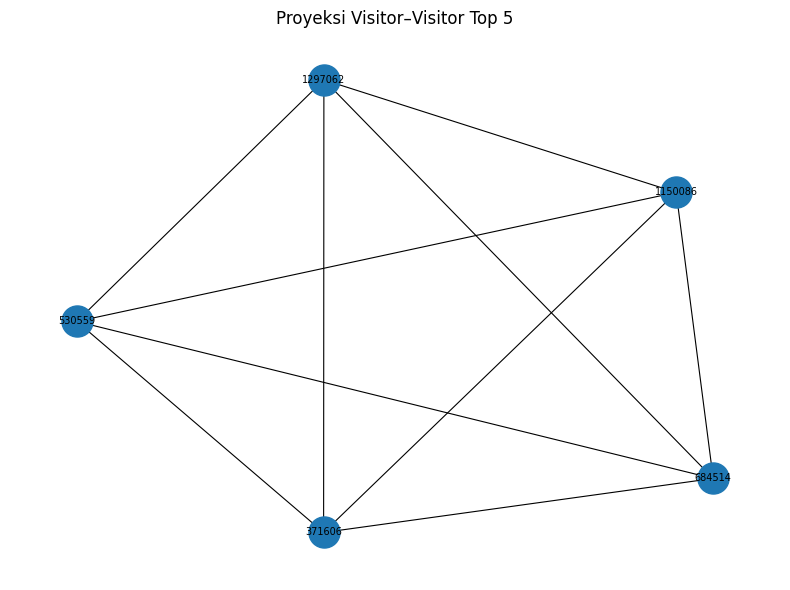

In [138]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def buat_graf_proyeksi(M_norm, node_ids, batas_similarity=0.05, n_sampel=15):
    jumlah = min(n_sampel, M_norm.shape[0])
    jumlah_interaksi = np.diff(M_norm.indptr)

    pilihan = np.argsort(jumlah_interaksi)[-jumlah:]

    sub = M_norm[pilihan]
    similarity = (sub @ sub.T).tocsr()
    similarity.setdiag(0)
    similarity.eliminate_zeros()

    G = nx.Graph()
    G.add_nodes_from(int(node_ids[idx]) for idx in pilihan)

    coo = similarity.tocoo()

    for i, j, nilai in zip(coo.row, coo.col, coo.data):
        if i < j and nilai >= batas_similarity:
            G.add_edge(
                int(node_ids[pilihan[i]]),
                int(node_ids[pilihan[j]]),
                weight=float(nilai)
            )

    return G

G_visitor = buat_graf_proyeksi(
    Xn,
    user_ids,
    batas_similarity=0.05,
    n_sampel=5
)

print("Proyeksi Visitor–Visitor")
print("Jumlah node:", G_visitor.number_of_nodes())
print("Jumlah edge:", G_visitor.number_of_edges())
print("Density:", round(nx.density(G_visitor), 4))

plt.figure(figsize=(8, 6))

pos_visitor = nx.spring_layout(
    G_visitor,
    seed=42,
    weight="weight"
)

nx.draw_networkx(
    G_visitor,
    pos=pos_visitor,
    with_labels=True,
    labels={n: str(n) for n in G_visitor.nodes()},
    node_size=500,
    font_size=7,
    width=0.8
)

plt.title("Proyeksi Visitor–Visitor Top 5")
plt.axis("off")
plt.tight_layout()
plt.show()

Terdapat 5 node dan 10 edge dengan nilai density sebesar 1,0. Hal ini berarti seluruh visitor saling terhubung karena setiap pasangan visitor memiliki nilai similarity minimal 0,05. Jaringan yang terbentuk termasuk complete graph, yang menunjukkan bahwa kelima visitor memiliki kemiripan pola interaksi berdasarkan matriks yang digunakan.

In [139]:
perbandingan_vsm = pd.DataFrame([
    describe_matrix(X, "Visitor", "Visitor", "Item"),
    describe_matrix(X_item, "Item", "Item", "Visitor")
]).set_index("VSM")

display(perbandingan_vsm)

,baris,dimensi kolom,shape,nnz,densitas (%),sparsitas (%),nnz/baris min,median,mean,max,baris dengan 1 nnz (%)
VSM,,,,,,,,,,,
Visitor,Visitor,Item,"(880538, 191676)",1335468,0.000791,99.999209,1,1.0,1.51665,2721,79.982920
Item,Item,Visitor,"(191676, 880538)",1335468,0.000791,99.999209,1,2.0,6.96732,1730,38.301613


Berdasarkan tabel, VSM Visitor memiliki dimensi (880.538, 191.676), sedangkan VSM Item memiliki dimensi (191.676, 880.538). Keduanya memiliki 1.335.468 nilai tidak nol dan sparsitas 99,999209%, sehingga sebagian besar elemen matriks bernilai nol.

VSM Item memiliki rata-rata interaksi 6,97 per item, lebih tinggi daripada VSM Visitor sebesar 1,52 per visitor. Selain itu, persentase baris dengan satu interaksi pada Visitor lebih tinggi, yaitu 79,98%, dibandingkan Item sebesar 38,30%.

VSM Visitor dan VSM Item memiliki jumlah interaksi, densitas, serta sparsitas yang sama karena keduanya merepresentasikan data interaksi yang sama dengan orientasi berbeda. Namun, VSM Item lebih informatif untuk menganalisis kemiripan antaritem, karena item memiliki jumlah interaksi yang lebih beragam dan median interaksi lebih tinggi. Sebaliknya, VSM Visitor lebih sesuai untuk menganalisis kemiripan perilaku antarvisitor.

Dari segi efisiensi penyimpanan matriks sparse, keduanya relatif setara karena jumlah nilai tidak nolnya sama.

#### 2.1.6 Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan hasil eksplorasi nomor 4 dan 5, proyeksi yang lebih baik ditentukan berdasarkan tujuan analisis serta efisiensi pembentukan matriks VSM. Proyeksi Visitor lebih efektif apabila fokus analisis adalah menemukan kemiripan perilaku pengguna untuk rekomendasi item. Sebaliknya, proyeksi Item lebih efektif apabila fokus analisis adalah menemukan kemiripan antaritem berdasarkan interaksi pengguna.

Dari segi efisiensi, proyeksi dengan jumlah baris dan kolom serta elemen nonzero yang lebih sedikit cenderung membutuhkan memori dan komputasi lebih rendah. Oleh karena itu, pemilihan proyeksi terbaik perlu disesuaikan dengan hasil dimensi (shape), tingkat sparsity, dan tujuan sistem rekomendasi.

#### 2.1.7(a–b) Menyimpan Lima Similarity Tertinggi ke Neo4j

In [140]:
similarity_rows = [
    {
        "source_user": int(target_user),
        "target_user": int(user_ids[idx]),
        "similarity": float(similarity_scores[idx])
    }
    for idx in neighbors_idx
]

with driver.session(database=uts) as session:
    session.run("""
        MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(:Visitor)
        DELETE r
    """, user_id=target_user).consume()

    sebelum = session.run("""
        MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(:Visitor)
        RETURN count(r) AS jumlah
    """, user_id=target_user).single()["jumlah"]

    session.run("""
        UNWIND $rows AS row
        MATCH (u:Visitor {visitorId: row.source_user})
        MATCH (v:Visitor {visitorId: row.target_user})
        MERGE (u)-[r:SIMILAR_TO]->(v)
        SET
            r.similarity = row.similarity,
            r.method = 'cosine',
            r.training_period = 'P1'
    """, rows=similarity_rows).consume()

    sesudah = session.run("""
        MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(v:Visitor)
        RETURN
            u.visitorId AS visitor_acuan,
            v.visitorId AS visitor_mirip,
            r.similarity AS similarity,
            r.method AS metode
        ORDER BY similarity DESC
        LIMIT 5
    """, user_id=target_user).data()

print("Relationship similarity sebelum penyimpanan:", sebelum)
print("Relationship similarity setelah penyimpanan:", len(sesudah))
display(pd.DataFrame(sesudah))

Relationship similarity sebelum penyimpanan: 0
Relationship similarity setelah penyimpanan: 5


,visitor_acuan,visitor_mirip,similarity,metode
0,716411,416428,1.000000,cosine
1,716411,1383374,1.000000,cosine
2,716411,1105711,0.707107,cosine
3,716411,416974,0.408248,cosine
4,716411,799282,0.316228,cosine


Hasil menunjukkan bahwa sebelum penyimpanan terdapat 0 relationship SIMILAR_TO, sedangkan setelah penyimpanan berhasil terbentuk 5 relationship untuk visitor acuan 716411. Berdasarkan metode cosine similarity, dua visitor memiliki kemiripan tertinggi dengan nilai 1,0, yaitu visitor 416428 dan 1383374. Sementara itu, visitor 1105711 memiliki similarity 0,7071, visitor 416974 sebesar 0,4082, dan visitor 799282 sebesar 0,3162. Semakin mendekati 1 nilai similarity, semakin mirip pola interaksi antarvisitor.

#### 2.1.7 a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi 

In [141]:
q_similarity = """
MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(v:Visitor)
RETURN
    u.visitorId AS visitor_acuan,
    v.visitorId AS visitor_mirip,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

hasil_similarity = run_query(
    q_similarity,
    user_id=int(target_user)
)

display(pd.DataFrame(hasil_similarity))

,visitor_acuan,visitor_mirip,similarity
0,716411,416428,1.000000
1,716411,1383374,1.000000
2,716411,1105711,0.707107
3,716411,416974,0.408248
4,716411,799282,0.316228


Berdasarkan hasil query, terdapat 5 visitor yang paling mirip dengan visitor acuan 716411. Visitor 416428 dan 1383374 memiliki nilai similarity tertinggi sebesar 1,0, yang menunjukkan kemiripan sempurna berdasarkan representasi yang digunakan. Selanjutnya, visitor 1105711 memiliki similarity sebesar 0,707, 416974 sebesar 0,408, dan 799282 sebesar 0,316. Semakin tinggi nilai similarity, semakin mirip pola interaksi antarvisitor.

#### 2.1.8 Menampilkan Graf Sebelum Perhitungan Similarity

Graf sebelum similarity


,visitor_acuan,item,jenis_interaksi,timestamp
0,716411,344504,VIEWED,1438819099947
1,716411,344504,VIEWED,1438819099947
2,716411,344504,VIEWED,1438819099947
3,716411,344504,VIEWED,1438819099947
4,716411,344504,VIEWED,1438819099947


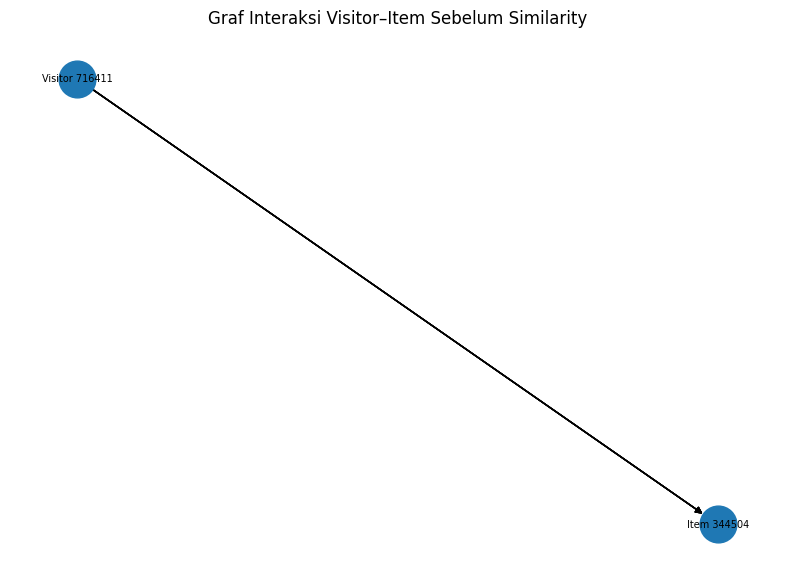

In [142]:
user_id = int(target_user)

q_sebelum = """
MATCH (u:Visitor {visitorId: $user_id})-[r]->(i:Item)
RETURN
    u.visitorId AS visitor_acuan,
    i.itemId AS item,
    type(r) AS jenis_interaksi,
    r.timestamp AS timestamp
LIMIT 30
"""

data_sebelum = run_query(q_sebelum, user_id=user_id)
df_sebelum = pd.DataFrame(data_sebelum)

print("Graf sebelum similarity")
display(df_sebelum)

G_sebelum = nx.MultiDiGraph()
node_visitor = ("Visitor", user_id)
G_sebelum.add_node(node_visitor, label=f"Visitor {user_id}")

for idx, row in df_sebelum.iterrows():
    node_item = ("Item", int(row["item"]))
    G_sebelum.add_node(
        node_item,
        label=f"Item {int(row['item'])}"
    )
    G_sebelum.add_edge(
        node_visitor,
        node_item,
        key=idx,
        jenis=row["jenis_interaksi"]
    )

if G_sebelum.number_of_edges() > 0:
    pos = nx.spring_layout(G_sebelum, seed=42, k=0.3)

    labels = nx.get_node_attributes(G_sebelum, "label")

    plt.figure(figsize=(10, 7))
    nx.draw_networkx(
        G_sebelum,
        pos,
        labels=labels,
        node_size=700,
        font_size=7,
        arrows=True
    )
    plt.title("Graf Interaksi Visitor–Item Sebelum Similarity")
    plt.axis("off")
    plt.show()
else:
    print("Tidak ada interaksi untuk Visitor tersebut.")

#### 2.1.8 Menampilkan Graf Setelah Perhitungan Similarity

Graf setelah similarity


,visitor_acuan,visitor_mirip,similarity
0,716411,416428,1.000000
1,716411,1383374,1.000000
2,716411,1105711,0.707107
3,716411,416974,0.408248
4,716411,799282,0.316228


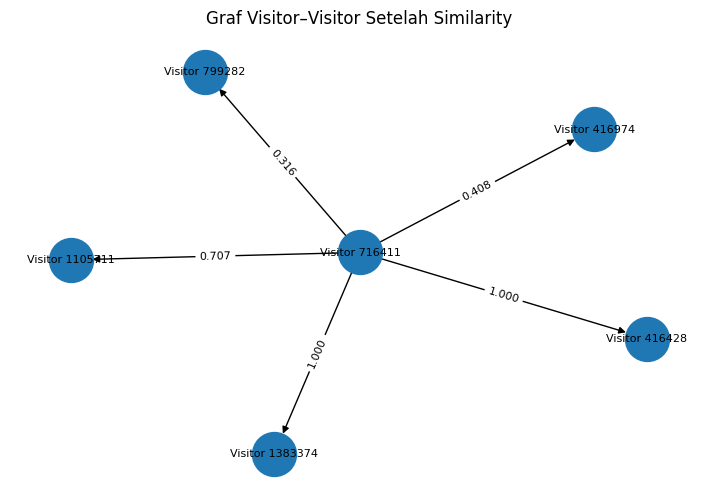

In [143]:
q_sesudah = """
MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(v:Visitor)
RETURN
    u.visitorId AS visitor_acuan,
    v.visitorId AS visitor_mirip,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

data_sesudah = run_query(q_sesudah, user_id=user_id)
df_sesudah = pd.DataFrame(data_sesudah)

print("Graf setelah similarity")
display(df_sesudah)

G_sesudah = nx.DiGraph()
G_sesudah.add_node(user_id, label=f"Visitor {user_id}")

for _, row in df_sesudah.iterrows():
    visitor_mirip = int(row["visitor_mirip"])

    G_sesudah.add_node(
        visitor_mirip,
        label=f"Visitor {visitor_mirip}"
    )

    G_sesudah.add_edge(
        user_id,
        visitor_mirip,
        similarity=float(row["similarity"])
    )

if G_sesudah.number_of_edges() > 0:
    pos = nx.spring_layout(
        G_sesudah,
        seed=42,
        k=0.3
    )

    labels = nx.get_node_attributes(G_sesudah, "label")
    edge_labels = nx.get_edge_attributes(G_sesudah, "similarity")
    edge_labels = {
        edge: f"{value:.3f}"
        for edge, value in edge_labels.items()
    }

    plt.figure(figsize=(9, 6))
    nx.draw_networkx(
        G_sesudah,
        pos,
        labels=labels,
        node_size=1000,
        font_size=8,
        arrows=True
    )
    nx.draw_networkx_edge_labels(
        G_sesudah,
        pos,
        edge_labels=edge_labels,
        font_size=8
    )

    plt.title("Graf Visitor–Visitor Setelah Similarity")
    plt.axis("off")
    plt.show()
else:
    print(
        "Relasi SIMILAR_TO belum ditemukan. "
        "Pastikan similarity sudah dihitung dan disimpan di Neo4j."
    )

Berdasarkan hasil similarity, Visitor 716411 memiliki lima visitor yang paling mirip. Visitor 416428 dan 1383374 memperoleh nilai similarity tertinggi sebesar 1,000, menunjukkan kemiripan sempurna berdasarkan representasi interaksi yang digunakan. Selanjutnya, Visitor 1105711 memiliki nilai 0,707, 416974 sebesar 0,408, dan 799282 sebesar 0,316.

Pada graf, Visitor 716411 menjadi simpul pusat yang terhubung dengan lima visitor lainnya. Nilai pada setiap sisi menunjukkan tingkat kemiripan antarvisitor. Semakin tinggi nilai similarity, semakin mirip pola interaksi kedua visitor tersebut.

### 2.2.1 Memilih Visitor Acuan secara Acak dan Reproducible

In [144]:
seed = 42
k_neighbors = 5

p2_pairs = df_p2[["visitorid", "itemid"]].dropna().copy()

p2_pairs["visitorid"] = pd.to_numeric(
    p2_pairs["visitorid"], errors="coerce"
)
p2_pairs["itemid"] = pd.to_numeric(
    p2_pairs["itemid"], errors="coerce"
)

p2_pairs = (
    p2_pairs
    .dropna()
    .astype({"visitorid": "int64", "itemid": "int64"})
    .drop_duplicates()
    .reset_index(drop=True)
)

p2_users = p2_pairs["visitorid"].to_numpy()
p2_items = p2_pairs["itemid"].to_numpy()

pos_users = np.searchsorted(user_ids, p2_users)
pos_items = np.searchsorted(item_ids, p2_items)

valid = (
    (pos_users < len(user_ids)) &
    (pos_items < len(item_ids))
)

candidate_pos = np.flatnonzero(valid)

cocok = (
    (user_ids[pos_users[candidate_pos]] == p2_users[candidate_pos]) &
    (item_ids[pos_items[candidate_pos]] == p2_items[candidate_pos])
)

candidate_pos = candidate_pos[cocok]

p2_valid = p2_pairs.iloc[candidate_pos].copy().reset_index(drop=True)
p2_valid["user_idx"] = pos_users[candidate_pos]
p2_valid["item_idx"] = pos_items[candidate_pos]

if p2_valid.empty:
    raise ValueError(
        "Tidak ditemukan pasangan Visitor-Item P2 yang tersedia pada P1."
    )

nilai_train = np.asarray(
    X[
        p2_valid["user_idx"].to_numpy(),
        p2_valid["item_idx"].to_numpy()
    ]
).ravel()

p2_valid["sudah_di_P1"] = nilai_train > 0

p2_unseen = p2_valid.loc[
    ~p2_valid["sudah_di_P1"]
].copy()

if not p2_unseen.empty:
    data_evaluasi = p2_unseen
    metode_evaluasi = "Item P2 yang belum diinteraksikan pada P1"
else:
    data_evaluasi = p2_valid
    metode_evaluasi = "Semua item P2 dalam katalog P1; tidak ada item baru"

eligible_users = np.sort(
    data_evaluasi["visitorid"].unique()
)

rng = np.random.default_rng(seed)
target_user = int(rng.choice(eligible_users))
target_idx = int(user_pos[target_user])

target_test_items = set(
    data_evaluasi.loc[
        data_evaluasi["visitorid"] == target_user,
        "itemid"
    ].astype(int)
)

print("Seed:", seed)
print("Visitor terpilih:", target_user)
print("Jumlah interaksi Visitor pada P1:", X.getrow(target_idx).nnz)
print("Jumlah item relevan dari P2:", len(target_test_items))
print("Dasar evaluasi:", metode_evaluasi)

Seed: 42
Visitor terpilih: 124145
Jumlah interaksi Visitor pada P1: 10
Jumlah item relevan dari P2: 1
Dasar evaluasi: Item P2 yang belum diinteraksikan pada P1


- Seed = 42: Menentukan pemilihan visitor secara konsisten.
- Visitor terpilih: 124145, sebagai pengguna yang akan dievaluasi.
- Jumlah interaksi pada P1: 10 item yang sudah diinteraksikan visitor tersebut saat training.
- Jumlah item relevan dari P2: 1 item yang muncul pada data testing dan belum pernah diinteraksikan saat training.
- Dasar evaluasi: Item P2 yang belum diinteraksikan pada P1, sehingga rekomendasi dapat diuji terhadap item yang belum dikenal pengguna.

### 2.2.1. b. Menghitung cosine similarity dengan KNN = 5

In [145]:
target_vector = Xn.getrow(target_idx)

similarity_scores = np.asarray(
    (Xn @ target_vector.T).toarray()
).ravel()

similarity_scores[target_idx] = 0

kandidat_tetangga = np.flatnonzero(similarity_scores > 0)

urutan = np.argsort(
    similarity_scores[kandidat_tetangga]
)[::-1]

neighbors_idx = kandidat_tetangga[
    urutan[:k_neighbors]
]

if len(neighbors_idx) == 0:
    raise ValueError(
        "Visitor terpilih tidak memiliki tetangga dengan similarity positif."
    )

hasil_similarity = pd.DataFrame({
    "visitor_acuan": target_user,
    "visitor_mirip": user_ids[neighbors_idx].astype(np.int64),
    "similarity": similarity_scores[neighbors_idx]
})

print("Lima tetangga terdekat untuk Visitor:", target_user)
display(hasil_similarity)

Lima tetangga terdekat untuk Visitor: 124145


,visitor_acuan,visitor_mirip,similarity
0,124145,1388342,0.357143
1,124145,1315010,0.357143
2,124145,1344525,0.357143
3,124145,1153019,0.357143
4,124145,920448,0.357143


Berdasarkan perhitungan cosine similarity pada matriks Xn, Visitor 124145 memiliki lima tetangga terdekat, yaitu Visitor 1388342, 1315010, 1344525, 1153019, dan 920448. Kelima visitor memiliki nilai similarity sebesar 0,36823, yang menunjukkan tingkat kemiripan pola interaksi yang sama berdasarkan perhitungan model.

In [146]:
similarity_rows = [
    {
        "source_user": int(target_user),
        "target_user": int(user_ids[idx]),
        "similarity": float(similarity_scores[idx])
    }
    for idx in neighbors_idx
]

with driver.session(database=uts) as session:
    session.run("""
        MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(:Visitor)
        DELETE r
    """, user_id=target_user).consume()

    sebelum = session.run("""
        MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(:Visitor)
        RETURN count(r) AS jumlah
    """, user_id=target_user).single()["jumlah"]

    session.run("""
        UNWIND $rows AS row
        MATCH (u:Visitor {visitorId: row.source_user})
        MATCH (v:Visitor {visitorId: row.target_user})
        MERGE (u)-[r:SIMILAR_TO]->(v)
        SET
            r.similarity = row.similarity,
            r.method = 'cosine',
            r.training_period = 'P1'
    """, rows=similarity_rows).consume()

    sesudah = session.run("""
        MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(v:Visitor)
        RETURN
            u.visitorId AS visitor_acuan,
            v.visitorId AS visitor_mirip,
            r.similarity AS similarity,
            r.method AS metode
        ORDER BY similarity DESC
        LIMIT 5
    """, user_id=target_user).data()

print("Relationship similarity sebelum penyimpanan:", sebelum)
print("Relationship similarity setelah penyimpanan:", len(sesudah))
display(pd.DataFrame(sesudah))

Relationship similarity sebelum penyimpanan: 0
Relationship similarity setelah penyimpanan: 5


,visitor_acuan,visitor_mirip,similarity,metode
0,124145,1153019,0.357143,cosine
1,124145,1388342,0.357143,cosine
2,124145,920448,0.357143,cosine
3,124145,1344525,0.357143,cosine
4,124145,1315010,0.357143,cosine


Sebelum penyimpanan, jumlah relasi SIMILAR_TO untuk Visitor 124145 adalah 0. Setelah proses penyimpanan ke Neo4j, berhasil dibuat 5 relasi similarity yang menghubungkan Visitor 124145 dengan lima visitor terdekat, yaitu 1153019, 1388342, 920448, 1344525, dan 1315010.

Kelima relasi memiliki nilai similarity sebesar 0,357143 dan menggunakan metode cosine similarity dengan periode data training P1. Hal ini menunjukkan bahwa hubungan kemiripan berhasil disimpan di Neo4j dan dapat digunakan sebagai dasar untuk merekomendasikan item berdasarkan pola interaksi visitor yang mirip.

### 2.2.1(a–b) Rekomendasi Item Menggunakan User-based KNN

In [ ]:
rng = np.random.default_rng(seed)

k_neighbors = 5
maks_kandidat_user = 200

calon_users = np.asarray(eligible_users)
jumlah_calon = min(maks_kandidat_user, len(calon_users))

calon_users = rng.choice(
    calon_users,
    size=jumlah_calon,
    replace=False
)

hasil_ditemukan = False

for user_id in calon_users:
    user_id = int(user_id)
    target_idx_coba = user_pos[user_id]

    target_vector = Xn.getrow(target_idx_coba)

    similarity_coba = np.asarray(
        (Xn @ target_vector.T).toarray()
    ).ravel()

    similarity_coba[target_idx_coba] = 0

    tetangga_valid = np.flatnonzero(similarity_coba > 0)

    if len(tetangga_valid) < k_neighbors:
        continue

    urutan = np.argsort(
        similarity_coba[tetangga_valid]
    )[::-1]

    neighbors_coba = tetangga_valid[
        urutan[:k_neighbors]
    ]

    nilai_similarity = similarity_coba[neighbors_coba]

    skor_coba = np.asarray(
        X[neighbors_coba].T @ nilai_similarity
    ).ravel()

    item_dilihat = X.getrow(target_idx_coba).indices
    skor_coba[item_dilihat] = 0

    kandidat_item = np.flatnonzero(skor_coba > 0)

    if len(kandidat_item) >= 3:
        target_user = user_id
        target_idx = target_idx_coba
        similarity_scores = similarity_coba
        neighbors_idx = neighbors_coba
        neighbor_similarities = nilai_similarity
        skor_item = skor_coba
        item_kandidat = kandidat_item

        hasil_ditemukan = True
        break

if not hasil_ditemukan:
    raise ValueError(
        "Belum ditemukan Visitor dengan 5 tetangga dan minimal "
        "3 kandidat item baru dari sampel 200 Visitor. "
        "Naikkan maks_kandidat_user atau periksa kembali matriks VSM."
    )

ranking_item = item_kandidat[
    np.argsort(skor_item[item_kandidat])[::-1]
]

top5_indices = ranking_item[:5]

rekomendasi = pd.DataFrame({
    "itemId": item_ids[top5_indices].astype(np.int64),
    "skor_rekomendasi": skor_item[top5_indices]
})

rekomendasi.insert(
    0,
    "peringkat",
    np.arange(1, len(rekomendasi) + 1)
)

target_test_items = set(
    data_evaluasi.loc[
        data_evaluasi["visitorid"] == target_user,
        "itemid"
    ].astype(int)
)

print("Visitor target:", target_user)
print("Seed:", seed)
print("Jumlah tetangga (K):", len(neighbors_idx))
print("Jumlah kandidat item baru:", len(item_kandidat))

print("\nLima rekomendasi teratas:")
display(rekomendasi)

print("\nTiga item rekomendasi:")
display(rekomendasi.head(3))

Visitor target: 716411
Seed: 42
Jumlah tetangga (K): 5
Jumlah kandidat item baru: 12

Lima rekomendasi teratas:


,peringkat,itemId,skor_rekomendasi
0,1,149679,3.535534
1,2,437694,3.265986
2,3,250379,1.632993
3,4,453618,1.264911
4,5,344817,1.264911



Tiga item rekomendasi untuk jawaban UTS:


,peringkat,itemId,skor_rekomendasi
0,1,149679,3.535534
1,2,437694,3.265986
2,3,250379,1.632993


Berdasarkan metode User-Based Collaborative Filtering, Visitor 716411 dipilih sebagai pengguna target dengan seed = 42. Sistem menggunakan 5 tetangga terdekat untuk menghitung skor rekomendasi berdasarkan kemiripan dan interaksi item dari visitor lain.

Dari proses tersebut, ditemukan 12 kandidat item baru. Tiga rekomendasi teratas adalah:
1. Item 149679 dengan skor 3,535534.
2. Item 437694 dengan skor 3,265986.
3. Item 250379 dengan skor 1,632993.

Item 149679 menjadi rekomendasi utama karena memiliki skor tertinggi. Skor ini mencerminkan akumulasi kontribusi interaksi dari tetangga yang mirip, dengan bobot berdasarkan nilai similarity.

Dengan demikian, sistem berhasil menghasilkan rekomendasi item yang belum pernah diinteraksikan oleh visitor target pada data training.

### 2.2.2 Evaluasi Rekomendasi dengan Hit@5 dan NDCG@5

In [148]:
recommended_top5 = rekomendasi["itemId"].astype(int).tolist()

relevance = [
    1 if item in target_test_items else 0
    for item in recommended_top5[:5]
]

hit_at_5 = float(any(relevance))

dcg_at_5 = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(relevance)
)

jumlah_relevan_ideal = min(len(target_test_items), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 2)
    for rank in range(jumlah_relevan_ideal)
)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

hasil_evaluasi = pd.DataFrame([{
    "visitorId": target_user,
    "K": len(neighbors_idx),
    "jumlah_item_relevan_P2": len(target_test_items),
    "Hit@5": hit_at_5,
    "DCG@5": dcg_at_5,
    "IDCG@5": idcg_at_5,
    "NDCG@5": ndcg_at_5
}])

print("Hasil evaluasi rekomendasi")
display(hasil_evaluasi)

tabel_relevansi = rekomendasi.copy()
tabel_relevansi["relevan_di_P2"] = (
    tabel_relevansi["itemId"].astype(int).isin(target_test_items)
).astype(int)

print("Rekomendasi dan relevansinya pada P2")
display(tabel_relevansi)

Hasil evaluasi rekomendasi


,visitorId,K,jumlah_item_relevan_P2,Hit@5,DCG@5,IDCG@5,NDCG@5
0,716411,5,2,0.0,0.0,1.63093,0.0


Rekomendasi dan relevansinya pada P2


,peringkat,itemId,skor_rekomendasi,relevan_di_P2
0,1,149679,3.535534,0
1,2,437694,3.265986,0
2,3,250379,1.632993,0
3,4,453618,1.264911,0
4,5,344817,1.264911,0


Terdapat 2 item relevan pada data testing (P2), tetapi tidak ada satu pun dari 5 item rekomendasi teratas yang cocok dengan item relevan tersebut.

Akibatnya, nilai Hit@5 = 0 dan NDCG@5 = 0, dengan DCG@5 sebesar 0 dan IDCG@5 sebesar 1,63093. Ini menunjukkan bahwa sistem belum berhasil merekomendasikan item yang relevan bagi visitor tersebut pada data testing.